# مخطط خلايا Fine-Tuning لنموذج الخط السامري

هذا الدفتر يأخذ الوزن الناتج عن مرحلة **Pretraining** (المُدرَّب على بيانات اصطناعية) ويُكمّل تدريبه (fine-tune) على **200 صورة حقيقية** موسومة يدويا، موجودة في:

`/content/drive/MyDrive/OCR_Alsameri_Lang_1/Real_Image_200/{image, label}`

| الخلية | الاسم | عملها |
|---:|---|---|
| 0 | **Mount & Installs** | تركيب Drive، تثبيت `ultralytics`، واستيراد المكتبات (numpy وOpenCV لكل عمليات المعالجة والتشويش، بدون أي مكتبة تشويش خارجية). |
| 1 | **Classes & Colors** | نفس الأصناف الـ23 (22 حرفا + DOT) ورموزها الطويلة بالضبط كما في دفتر التوليد، لضمان توافق الأوزان. |
| 2 | **FT_CONFIG** | القاموس المرجعي لكل مسارات ونسب وإعدادات هذه المرحلة. |
| 3 | **نسخ البيانات الحقيقية إلى كولاب** | نسخ `image/` و`label/` من الدرايف إلى مساحة عمل مؤقتة محليا، مع مطابقة كل صورة بتسميتها والتحذير من أي نقص. **البيانات الأصلية في الدرايف لا تُمس إطلاقا.** |
| 4 | **فحص جودة التسميات (QA)** | تتحقق من صحة صيغة YOLO لكل ملف تسمية (نطاق الصنف، الإحداثيات ضمن [0,1])، وتطبع توزيع الأصناف. |
| 5 | **قنوات التشويش القوي** | تبني تحويلات مكتوبة يدويا بـ numpy وOpenCV فقط (هندسية عبر warpAffine/warpPerspective + لونية + ضوضاء + ضبابية + ظل + ضغط JPEG) مع تحديث صناديق الإحاطة يدويا بتحويل أركانها، ونسخة احتياطية أخف إن حذفت القناة القوية أغلب الصناديق. |
| 6 | **تطبيق التشويش مرة واحدة** | لكل صورة حقيقية تشويشة واحدة فقط: 200 صورة → 400 (200 أصلية + 200 مشوشة)، تُحفظ محليا في كولاب فقط. |
| 7 | **معاينة أصلية/مشوشة** | رسم عينة عشوائية جنبا إلى جنب للتأكد بصريا من صحة الصناديق بعد التشويش. |
| 8 | **تقسيم 70/15/15** | تقسيم حتمي بذرة ثابتة إلى تدريب/تحقق/اختبار **على مستوى الصورة الأصلية** (تمنع تسرّب نسخة الصورة المشوشة لنفس الصورة الأصلية إلى مجموعة أخرى)، ثم بناء هيكل مجلدات YOLO. |
| 9 | **data.yaml** | كتابة ملف بيانات YOLO يشير إلى مسارات كولاب المؤقتة بنفس أسماء الأصناف الـ23. |
| 10 | **Fine-Tune Training** | تحميل الوزن المُدرَّب مسبقا وإكمال تدريبه بمعدل تعلّم منخفض، وحفظ النتائج في `Real_Image_200/Model_fintune` على الدرايف. |
| 11 | **تقييم على الاختبار** | تقييم أفضل وزن على مجموعة الاختبار المعزولة (15%) وطباعة المقاييس. |
| 12 | **اختبار تفاعلي** | رفع صورة من جهازك، رسم الصناديق المتوقعة عليها، واستخراج النص المقروء منها. |

> ⚠️ **ملاحظة على نسب التقسيم**: طلبت التقسيم كـ «15 و15 و70» بترتيب (تدريب، اختبار، تحقق). اعتمدتُ العرف القياسي في تعلّم الآلة وهو أن **التدريب هو الحصة الأكبر (70%)** بينما التحقق والاختبار 15% لكل منهما — لأن تدريب نموذج بـ 15% فقط من بيانات حقيقية قليلة أصلا (200 صورة) سيضعف النتيجة كثيرا. النسب الثلاث معرّفة في خلية `FT_CONFIG` بوضوح تام (`split.train` / `split.val` / `split.test`)؛ إن كنت تقصد ترتيبا مختلفا فغيّرها هناك فقط (المجموع يجب أن يبقى 1.0) وكل الخلايا التالية ستعمل تلقائيا بالنسب الجديدة.

تركّب Drive، تثبت `ultralytics` (مثبّت الإصدار لضمان ثبات أسماء المعاملات) و`pyyaml` و`opencv-python-headless`، وتستورد numpy وOpenCV وكل المكتبات المطلوبة لبقية الدفتر (بدون أي مكتبة تشويش خارجية مثل albumentations).


In [1]:
# ===================== الخلية 0: Mount & Installs =====================
from google.colab import drive
drive.mount('/content/drive')

!pip install -q ultralytics
!pip install -q pyyaml opencv-python-headless

import os
import sys
import json
import math
import random
import shutil
from pathlib import Path
from collections import Counter

import numpy as np
import cv2
import yaml
import matplotlib
import matplotlib.pyplot as plt

import ultralytics

print("ultralytics    :", ultralytics.__version__)
print("opencv         :", cv2.__version__)
print("numpy          :", np.__version__)


Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.5/46.5 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.1/78.1 kB 8.7 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
ultralytics    : 8.4.154
opencv         : 5.0.0
numpy          : 2.1.3


تعرّف الأصناف الثابتة الـ23 (22 حرفا سامريا + صنف النقطة DOT) بنفس الترتيب والرموز الحرفية تماما كما في دفتر Pretraining، لأن أي اختلاف في الترتيب يفسد توافق أوزان النموذج المُدرَّب مسبقا. المخرج: عدد الأصناف وقائمتها.

In [2]:
# ===================== الخلية 1: Classes & Colors =====================
# منسوخة حرفيا من دفتر التوليد/التدريب المسبق — لا تُغيَّر هذه الخلية أبدا
SAMARITAN_LETTERS = (
    (0, "ALAF", 0x0800), (1, "BIT", 0x0801), (2, "GAMAN", 0x0802), (3, "DALAT", 0x0803),
    (4, "IY", 0x0804), (5, "BAA", 0x0805), (6, "ZEN", 0x0806), (7, "IT", 0x0807),
    (8, "TIT", 0x0808), (9, "YUT", 0x0809), (10, "KAAF", 0x080A), (11, "LABAT", 0x080B),
    (12, "MIM", 0x080C), (13, "NUN", 0x080D), (14, "SINGAAT", 0x080E), (15, "IN", 0x080F),
    (16, "FI", 0x0810), (17, "TSAADIY", 0x0811), (18, "QUF", 0x0812), (19, "RISH", 0x0813),
    (20, "SHAN", 0x0814), (21, "TAAF", 0x0815),
)
DOT_CLASS_ID = 22
CLASS_NAMES = [name for _, name, _ in SAMARITAN_LETTERS] + ["DOT"]
NUM_CLASSES = len(CLASS_NAMES)
NUM_LETTERS = len(SAMARITAN_LETTERS)
LETTER_CODEPOINTS = [cp for _, _, cp in SAMARITAN_LETTERS]
assert NUM_LETTERS == 22 and NUM_CLASSES == 23

# نفس 23 لونا (tab20 + 3 من tab20b) المستخدمة في دفتر التوليد، للمعاينة والرسم هنا أيضا
CLASS_COLORS = [tuple(int(c * 255) for c in matplotlib.cm.tab20(i)[:3]) for i in range(20)] + \
               [tuple(int(c * 255) for c in matplotlib.cm.tab20b(i)[:3]) for i in range(3)]

print("عدد الأصناف:", NUM_CLASSES)
print("الأصناف   :", CLASS_NAMES)


عدد الأصناف: 23
الأصناف   : ['ALAF', 'BIT', 'GAMAN', 'DALAT', 'IY', 'BAA', 'ZEN', 'IT', 'TIT', 'YUT', 'KAAF', 'LABAT', 'MIM', 'NUN', 'SINGAAT', 'IN', 'FI', 'TSAADIY', 'QUF', 'RISH', 'SHAN', 'TAAF', 'DOT']


القاموس المرجعي الوحيد لهذه المرحلة: مسارات البيانات الحقيقية والوزن المُدرَّب مسبقا، نسب التقسيم، إعدادات التشويش، وإعدادات التدريب. كل الخلايا اللاحقة تقرأ منه فقط. المخرج: ملخص القيم الأساسية.

In [3]:
# ===================== الخلية 2: FT_CONFIG =====================
FT_CONFIG = {
    "paths": {
        # مصدر البيانات الحقيقية — لا يُكتب فيه أي شيء أبدا، قراءة فقط
        "real_data_dir": "/content/drive/MyDrive/OCR_Alsameri_Lang_1/Real_Image_200",
        "real_images_subdir": "image",
        "real_labels_subdir": "label",

        # وزن نموذج الـ Pretraining (مخرج خلية Train في دفتر التوليد). عدّله إذا كان مسارك مختلفا
        "pretrained_weights": "/content/drive/MyDrive/OCR_Alsameri_Lang_1/YOLO_Training/yolov8n_p2/weights/best.pt",

        # مساحة عمل مؤقتة داخل كولاب فقط (تُمحى مع انتهاء الجلسة، ولا تُنسخ إلى الدرايف)
        "local_work_dir": "/content/finetune_work",

        "data_yaml_filename": "data_finetune.yaml",

        # حيث يُحفظ نموذج الـ fine-tune النهائي على الدرايف (المسار المطلوب بالضبط)
        "output_model_dir": "/content/drive/MyDrive/OCR_Alsameri_Lang_1/Real_Image_200/Model_fintune",
    },

    "split": {
        # انظر ملاحظة النسب في أعلى الدفتر — غيّر هذه الثلاثة فقط إن أردت ترتيبا مختلفا
        "train": 0.70,
        "val": 0.15,
        "test": 0.15,
        "seed": 42,
    },

    "augmentation": {
        "seed": 42,
    },

    "train": {
        "epochs": 150,
        "batch": 16,
        "imgsz": 640,
        "patience": 40,          # إيقاف مبكر إن لم يتحسن mAP لهذا العدد من الإيبوكات
        "lr0": 0.0015,           # معدل تعلّم منخفض مناسب لإكمال تدريب (fine-tune) لا تدريب من الصفر
        "lrf": 0.01,
        "optimizer": "auto",
        "freeze": 0,             # عدد طبقات الـ backbone المجمَّدة؛ 0 = تدريب الشبكة كاملة
        "device": 0,             # 0 = أول GPU متاح، أو "cpu"
        "workers": 8,
        # نفس فلسفة دفتر التوليد: لا قلب أفقي/رأسي ولا دوران عشوائي كبير لأن اتجاه الحروف مهم
        "fliplr": 0.0,
        "flipud": 0.0,
        "degrees": 0.0,
        "mosaic": 0.3,
        "close_mosaic": 15,
        "hsv_h": 0.005,
        "hsv_s": 0.2,
        "hsv_v": 0.2,
    },
}

_split_sum = sum(FT_CONFIG["split"][k] for k in ("train", "val", "test"))
assert abs(_split_sum - 1.0) < 1e-6, f"نسب التقسيم يجب أن تجمع إلى 1.0 (الحالي {_split_sum})"

LOCAL_WORK_DIR = Path(FT_CONFIG["paths"]["local_work_dir"])
LOCAL_REAL_DIR = LOCAL_WORK_DIR / "real_copy"
LOCAL_AUG_DIR = LOCAL_WORK_DIR / "augmented"
LOCAL_DATASET_DIR = LOCAL_WORK_DIR / "dataset"
for _d in (LOCAL_REAL_DIR, LOCAL_AUG_DIR, LOCAL_DATASET_DIR):
    _d.mkdir(parents=True, exist_ok=True)

print("✓ FT_CONFIG جاهز")
print(f"مصدر البيانات الحقيقية  : {FT_CONFIG['paths']['real_data_dir']}")
print(f"الوزن المُدرَّب مسبقا    : {FT_CONFIG['paths']['pretrained_weights']}")
print(f"مجلد حفظ fine-tune       : {FT_CONFIG['paths']['output_model_dir']}")
print(f"مساحة العمل في كولاب     : {LOCAL_WORK_DIR}")
print(f"نسب التقسيم              : train={FT_CONFIG['split']['train']*100:.0f}%  "
      f"val={FT_CONFIG['split']['val']*100:.0f}%  test={FT_CONFIG['split']['test']*100:.0f}%")


✓ FT_CONFIG جاهز
مصدر البيانات الحقيقية  : /content/drive/MyDrive/OCR_Alsameri_Lang_1/Real_Image_200
الوزن المُدرَّب مسبقا    : /content/drive/MyDrive/OCR_Alsameri_Lang_1/YOLO_Training/yolov8n_p2/weights/best.pt
مجلد حفظ fine-tune       : /content/drive/MyDrive/OCR_Alsameri_Lang_1/Real_Image_200/Model_fintune
مساحة العمل في كولاب     : /content/finetune_work
نسب التقسيم              : train=70%  val=15%  test=15%


تنسخ `image/` و`label/` من الدرايف إلى مساحة عمل مؤقتة داخل كولاب، وتطابق كل صورة بملف تسميتها (نفس الاسم بامتداد `.txt`). أي صورة بلا تسمية تُستبعد مع تحذير صريح، ولا يُكتب أي شيء في مجلد الدرايف الأصلي.

In [ ]:
# ===================== الخلية 3: نسخ البيانات الحقيقية إلى كولاب =====================
REAL_SRC = Path(FT_CONFIG["paths"]["real_data_dir"])
IMG_SRC = REAL_SRC / FT_CONFIG["paths"]["real_images_subdir"]
LBL_SRC = REAL_SRC / FT_CONFIG["paths"]["real_labels_subdir"]

if not IMG_SRC.is_dir():
    raise FileNotFoundError(f"مجلد الصور غير موجود: {IMG_SRC}")
if not LBL_SRC.is_dir():
    raise FileNotFoundError(f"مجلد التسميات غير موجود: {LBL_SRC}")

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
image_files = sorted([p for p in IMG_SRC.iterdir() if p.suffix.lower() in IMG_EXTS])

pairs = []
missing_labels = []
for img_path in image_files:
    lbl_path = LBL_SRC / f"{img_path.stem}.txt"
    if lbl_path.exists():
        pairs.append((img_path, lbl_path))
    else:
        missing_labels.append(img_path.name)

print(f"إجمالي الصور الموجودة    : {len(image_files)}")
print(f"أزواج صالحة (صورة+تسمية) : {len(pairs)}")
if missing_labels:
    _shown = missing_labels[:10]
    _more = " ..." if len(missing_labels) > 10 else ""
    print(f"⚠ صور بلا ملف تسمية ({len(missing_labels)}): {_shown}{_more}")
if not pairs:
    raise RuntimeError("لا توجد أي أزواج صورة/تسمية صالحة — تحقق من مسارات FT_CONFIG['paths'].")

LOCAL_REAL_IMG_DIR = LOCAL_REAL_DIR / "images"
LOCAL_REAL_LBL_DIR = LOCAL_REAL_DIR / "labels"
LOCAL_REAL_IMG_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_REAL_LBL_DIR.mkdir(parents=True, exist_ok=True)

for img_path, lbl_path in pairs:
    shutil.copy2(img_path, LOCAL_REAL_IMG_DIR / img_path.name)
    shutil.copy2(lbl_path, LOCAL_REAL_LBL_DIR / lbl_path.name)

print(f"✓ نُسخت {len(pairs)} صورة و{len(pairs)} تسمية إلى: {LOCAL_REAL_DIR}  (مساحة كولاب المؤقتة فقط)")


إجمالي الصور الموجودة    : 200
أزواج صالحة (صورة+تسمية) : 200


تتحقق من صحة كل ملف تسمية بصيغة YOLO: خمسة حقول لكل سطر، رقم الصنف ضمن [0, 22]، والإحداثيات المطبّعة ضمن [0, 1]. الملف الفارغ (وثيقة بلا صناديق) مسموح. المخرج: عدد الصناديق الكلي، الملفات المعطوبة إن وُجدت، وتوزيع الأصناف.

In [ ]:
# ===================== الخلية 4: فحص جودة التسميات (QA) =====================
def validate_yolo_label(path, num_classes):
    '''يعيد قائمة رسائل مشاكل لملف تسمية واحد؛ قائمة فارغة يعني الملف سليم.'''
    problems = []
    if path.stat().st_size == 0:
        return problems  # ملف فارغ = وثيقة بلا صناديق، مسموح به
    with open(path, "r", encoding="utf-8") as f:
        lines = [l.strip() for l in f if l.strip()]
    for i, line in enumerate(lines):
        parts = line.split()
        if len(parts) != 5:
            problems.append(f"سطر {i}: عدد حقول غير صحيح ({len(parts)})")
            continue
        try:
            cls = int(float(parts[0]))
            xc, yc, w, h = (float(v) for v in parts[1:])
        except ValueError:
            problems.append(f"سطر {i}: قيم غير رقمية")
            continue
        if not (0 <= cls < num_classes):
            problems.append(f"سطر {i}: صنف خارج النطاق ({cls})")
        for v, name in zip((xc, yc, w, h), ("xc", "yc", "w", "h")):
            if not (0.0 <= v <= 1.0):
                problems.append(f"سطر {i}: {name}={v:.4f} خارج المدى [0,1]")
    return problems

total_boxes = 0
class_counter = Counter()
bad_files = []
empty_files = 0

for img_path, lbl_path in pairs:
    local_lbl = LOCAL_REAL_LBL_DIR / lbl_path.name
    problems = validate_yolo_label(local_lbl, NUM_CLASSES)
    if problems:
        bad_files.append((local_lbl.name, problems[:3]))
        continue
    if local_lbl.stat().st_size == 0:
        empty_files += 1
        continue
    with open(local_lbl, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                total_boxes += 1
                class_counter[int(float(line.split()[0]))] += 1

print(f"إجمالي الصناديق         : {total_boxes}")
print(f"ملفات فارغة (بلا صناديق): {empty_files}")
print(f"ملفات فيها مشاكل        : {len(bad_files)}")
for name, probs in bad_files[:10]:
    print(f"  ⚠ {name}: {probs}")

print("\nتوزيع الأصناف:")
for cls_id in range(NUM_CLASSES):
    print(f"  {CLASS_NAMES[cls_id]:10s}: {class_counter.get(cls_id, 0)}")

if bad_files:
    print("\n⚠ يوجد ملفات تسمية معطوبة — راجعها قبل المتابعة (لن يُوقَف التنفيذ تلقائيا).")


تبني قناتين من تحويلات مكتوبة يدويا بـ numpy وOpenCV فقط (بدون albumentations أو أي مكتبة مشابهة) متزامنة مع صناديق الإحاطة (bbox-aware): قناة **قوية** (Affine + Perspective + تشويه محلي ناعم + لونية + ضوضاء + ضبابية + ظل + ضغط JPEG + Coarse Dropout مجتمعة، بحيث تبدو الصورة الناتجة مختلفة فعليا عن الأصل) وقناة **احتياطية أخف** تُستخدم فقط إن حذفت القناة القوية أغلب صناديق صورة معينة. تُحدَّث الصناديق بتحويل أركانها الأربعة بنفس مصفوفة كل تحويل هندسي ثم قصّها وتصفيتها حسب نسبة الظهور المتبقية، بنفس منطق Albumentations الداخلي تماما لكن بكود مكتوب يدويا بالكامل.


In [ ]:
# ===================== الخلية 5: قنوات التشويش القوي (numpy + OpenCV فقط) =====================
# نفس فكرة الخلية الأصلية لكن بدون أي اعتماد على مكتبة albumentations أو أي مكتبة تشويش جاهزة أخرى:
# التحويلات الهندسية (Affine/Perspective) تُطبَّق على الصورة عبر cv2.warpAffine/warpPerspective،
# وتُحدَّث صناديق الإحاطة يدويا بتحويل أركانها الأربعة بنفس المصفوفة ثم أخذ أصغر مستطيل محيط
# (axis-aligned bounding box)، تماما بنفس المنطق الذي تستخدمه Albumentations داخليا.

def to_pixel_boxes(boxes_yolo, w, h):
    '''[xc,yc,w,h] نسبية إلى [x1,y1,x2,y2] بالبكسل.'''
    out = []
    for xc, yc, bw, bh in boxes_yolo:
        x1 = (xc - bw / 2.0) * w
        y1 = (yc - bh / 2.0) * h
        x2 = (xc + bw / 2.0) * w
        y2 = (yc + bh / 2.0) * h
        out.append([x1, y1, x2, y2])
    return out

def to_yolo_boxes(boxes_px, w, h):
    '''[x1,y1,x2,y2] بالبكسل إلى [xc,yc,w,h] نسبية، مع قص الحدود إلى داخل الصورة.'''
    out = []
    for x1, y1, x2, y2 in boxes_px:
        x1 = max(0.0, min(x1, w)); x2 = max(0.0, min(x2, w))
        y1 = max(0.0, min(y1, h)); y2 = max(0.0, min(y2, h))
        bw = (x2 - x1) / w
        bh = (y2 - y1) / h
        xc = ((x1 + x2) / 2.0) / w
        yc = ((y1 + y2) / 2.0) / h
        out.append([xc, yc, bw, bh])
    return out

def _box_corners(box_px):
    x1, y1, x2, y2 = box_px
    return np.array([[x1, y1], [x2, y1], [x2, y2], [x1, y2]], dtype=np.float32)

def transform_boxes_affine(boxes_px, M):
    '''M مصفوفة Affine بحجم 2x3 (نفس ما يقبله cv2.warpAffine).'''
    out = []
    for b in boxes_px:
        corners = _box_corners(b)
        ones = np.ones((4, 1), dtype=np.float32)
        corners_h = np.hstack([corners, ones])
        transformed = corners_h @ M.T
        xs, ys = transformed[:, 0], transformed[:, 1]
        out.append([float(xs.min()), float(ys.min()), float(xs.max()), float(ys.max())])
    return out

def transform_boxes_perspective(boxes_px, M):
    '''M مصفوفة Perspective بحجم 3x3 (نفس ما يقبله cv2.warpPerspective).'''
    out = []
    for b in boxes_px:
        corners = _box_corners(b)
        ones = np.ones((4, 1), dtype=np.float32)
        corners_h = np.hstack([corners, ones])
        transformed = corners_h @ M.T
        transformed = transformed[:, :2] / transformed[:, 2:3]
        xs, ys = transformed[:, 0], transformed[:, 1]
        out.append([float(xs.min()), float(ys.min()), float(xs.max()), float(ys.max())])
    return out

def clip_and_filter_boxes(boxes_px, classes, w, h, min_visibility=0.35, min_area_px=4):
    '''يقص الصناديق إلى حدود الصورة، ويحذف ما فقد أغلب مساحته أو أصبح صغيرا جدا
    (يماثل min_visibility/min_area في Albumentations).'''
    kept_boxes, kept_classes = [], []
    for (x1, y1, x2, y2), cls in zip(boxes_px, classes):
        orig_area = max(0.0, x2 - x1) * max(0.0, y2 - y1)
        if orig_area <= 0:
            continue
        cx1, cy1 = max(x1, 0.0), max(y1, 0.0)
        cx2, cy2 = min(x2, float(w)), min(y2, float(h))
        if cx2 <= cx1 or cy2 <= cy1:
            continue
        clipped_area = (cx2 - cx1) * (cy2 - cy1)
        if (clipped_area / orig_area) < min_visibility or clipped_area < min_area_px:
            continue
        kept_boxes.append([cx1, cy1, cx2, cy2])
        kept_classes.append(cls)
    return kept_boxes, kept_classes


# ---------- تحويلات هندسية ----------

def random_affine_matrix(w, h, rotate=(-8, 8), scale=(0.85, 1.15), translate_frac=0.06, shear=(-4, 4)):
    angle = random.uniform(*rotate)
    sc = random.uniform(*scale)
    sh = math.radians(random.uniform(*shear))
    tx = random.uniform(-translate_frac, translate_frac) * w
    ty = random.uniform(-translate_frac, translate_frac) * h
    cx, cy = w / 2.0, h / 2.0

    M_rot = cv2.getRotationMatrix2D((cx, cy), angle, sc)
    M_rot3 = np.vstack([M_rot, [0, 0, 1]]).astype(np.float32)
    M_shear3 = np.array([[1, math.tan(sh), -cy * math.tan(sh)],
                          [0, 1, 0],
                          [0, 0, 1]], dtype=np.float32)
    M = M_shear3 @ M_rot3
    M[0, 2] += tx
    M[1, 2] += ty
    return M[:2, :].astype(np.float32)

def apply_affine(image, M):
    h, w = image.shape[:2]
    return cv2.warpAffine(image, M, (w, h), borderMode=cv2.BORDER_REFLECT_101)

def random_perspective_matrix(w, h, scale=(0.03, 0.08)):
    s = random.uniform(*scale)
    dx, dy = s * w, s * h
    src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    jitter = np.random.uniform(-1, 1, size=src.shape).astype(np.float32) * [dx, dy]
    dst = src + jitter
    return cv2.getPerspectiveTransform(src, dst)

def apply_perspective(image, M):
    h, w = image.shape[:2]
    return cv2.warpPerspective(image, M, (w, h), borderMode=cv2.BORDER_REFLECT_101)

def elastic_distortion(image, alpha=30.0, sigma=6.0):
    '''تشويه محلي ناعم (بديل ElasticTransform/GridDistortion) — يُطبَّق على الصورة فقط؛
    الصناديق تُوسَّع بهامش أمان صغير بعده بدلا من إعادة حسابها بدقة، لأن الإزاحة صغيرة وناعمة.'''
    h, w = image.shape[:2]
    dx = (np.random.rand(h, w).astype(np.float32) * 2 - 1)
    dy = (np.random.rand(h, w).astype(np.float32) * 2 - 1)
    ksize = int(sigma * 3) | 1
    dx = cv2.GaussianBlur(dx, (ksize, ksize), sigma) * alpha
    dy = cv2.GaussianBlur(dy, (ksize, ksize), sigma) * alpha
    x, y = np.meshgrid(np.arange(w), np.arange(h))
    map_x = (x + dx).astype(np.float32)
    map_y = (y + dy).astype(np.float32)
    return cv2.remap(image, map_x, map_y, interpolation=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)


# ---------- تحويلات لونية وضوضاء وضبابية ----------

def adjust_brightness_contrast(image, brightness=0.0, contrast=0.0):
    img = image.astype(np.float32)
    img = img * (1.0 + contrast) + brightness * 255.0
    return np.clip(img, 0, 255).astype(np.uint8)

def adjust_hsv(image, hue_shift=0.0, sat_shift=0.0, val_shift=0.0):
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV).astype(np.int32)
    hsv[..., 0] = (hsv[..., 0] + hue_shift) % 180
    hsv[..., 1] = np.clip(hsv[..., 1] + sat_shift, 0, 255)
    hsv[..., 2] = np.clip(hsv[..., 2] + val_shift, 0, 255)
    return cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)

def adjust_gamma(image, gamma=1.0):
    inv = 1.0 / max(gamma, 1e-6)
    table = (np.linspace(0, 1, 256) ** inv * 255).astype(np.uint8)
    return cv2.LUT(image, table)

def apply_clahe(image, clip_limit=3.0):
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(8, 8))
    l2 = clahe.apply(l)
    return cv2.cvtColor(cv2.merge([l2, a, b]), cv2.COLOR_LAB2RGB)

def add_gaussian_noise(image, var_range=(15.0, 70.0)):
    var = random.uniform(*var_range)
    noise = np.random.normal(0, var ** 0.5, image.shape).astype(np.float32)
    return np.clip(image.astype(np.float32) + noise, 0, 255).astype(np.uint8)

def add_iso_noise(image, color_shift=0.06, intensity=(0.2, 0.6)):
    '''تقريب لـ ISONoise: ضوضاء على قناة السطوع + انزياح خفيف في اللون.'''
    inten = random.uniform(*intensity)
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV).astype(np.float32)
    hsv[..., 2] = np.clip(hsv[..., 2] + np.random.normal(0, inten * 30, hsv[..., 2].shape), 0, 255)
    hsv[..., 0] = (hsv[..., 0] + random.uniform(-color_shift, color_shift) * 20) % 180
    hsv[..., 1] = np.clip(hsv[..., 1] + random.uniform(-color_shift, color_shift) * 40, 0, 255)
    return cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)

def apply_gaussian_blur(image, ksize_range=(3, 7)):
    choices = [k for k in range(ksize_range[0], ksize_range[1] + 1) if k % 2 == 1]
    k = random.choice(choices)
    return cv2.GaussianBlur(image, (k, k), 0)

def apply_motion_blur(image, ksize_range=(3, 9)):
    choices = [k for k in range(ksize_range[0], ksize_range[1] + 1) if k % 2 == 1]
    k = random.choice(choices)
    kernel = np.zeros((k, k), dtype=np.float32)
    if random.random() < 0.5:
        kernel[k // 2, :] = 1.0
    else:
        kernel[:, k // 2] = 1.0
    kernel /= k
    return cv2.filter2D(image, -1, kernel)

def apply_random_shadow(image, num_shadows=(1, 2), max_pts=5):
    h, w = image.shape[:2]
    out = image.copy()
    for _ in range(random.randint(*num_shadows)):
        n_pts = random.randint(3, max_pts)
        pts = np.array([[random.randint(0, w - 1), random.randint(0, h - 1)] for _ in range(n_pts)], dtype=np.int32)
        mask = np.zeros((h, w), dtype=np.uint8)
        cv2.fillPoly(mask, [pts], 255)
        darken = random.uniform(0.5, 0.8)
        region = out[mask > 0].astype(np.float32) * darken
        out[mask > 0] = np.clip(region, 0, 255).astype(np.uint8)
    return out

def apply_jpeg_compression(image_rgb, quality_range=(35, 90)):
    quality = random.randint(*quality_range)
    bgr = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)
    ok, enc = cv2.imencode('.jpg', bgr, [int(cv2.IMWRITE_JPEG_QUALITY), quality])
    if not ok:
        return image_rgb
    dec = cv2.imdecode(enc, cv2.IMREAD_COLOR)
    return cv2.cvtColor(dec, cv2.COLOR_BGR2RGB)

def apply_coarse_dropout(image, max_holes=4, min_holes=1, max_h_frac=0.06, max_w_frac=0.06, fill_value=0):
    h, w = image.shape[:2]
    out = image.copy()
    for _ in range(random.randint(min_holes, max_holes)):
        hole_h = random.randint(1, max(1, int(max_h_frac * h)))
        hole_w = random.randint(1, max(1, int(max_w_frac * w)))
        y = random.randint(0, max(0, h - hole_h))
        x = random.randint(0, max(0, w - hole_w))
        out[y:y + hole_h, x:x + hole_w] = fill_value
    return out


# ---------- تجميع القنوات ----------

class AugPipeline:
    '''يطابق واجهة استدعاء Albumentations: pipeline(image=..., bboxes=..., class_labels=...)
    ويعيد dict فيه "image" و"bboxes" و"class_labels" — لتبقى بقية الدفتر (الخلية 6 وما بعدها) بلا أي تغيير.'''

    def __init__(self, strength="strong"):
        self.strength = strength
        if strength == "strong":
            self.min_visibility, self.min_area = 0.35, 4
        else:
            self.min_visibility, self.min_area = 0.20, 2

    def __call__(self, image, bboxes, class_labels):
        h, w = image.shape[:2]
        boxes_px = to_pixel_boxes(bboxes, w, h) if bboxes else []
        classes = list(class_labels)
        img = image.copy()
        elastic_margin = 0
        strong = self.strength == "strong"

        if random.random() < (0.9 if strong else 0.8):
            rot = (-8, 8) if strong else (-3, 3)
            sc = (0.85, 1.15) if strong else (0.95, 1.05)
            tf = 0.06 if strong else 0.02
            shear = (-4, 4) if strong else (0, 0)
            M = random_affine_matrix(w, h, rotate=rot, scale=sc, translate_frac=tf, shear=shear)
            img = apply_affine(img, M)
            if boxes_px:
                boxes_px = transform_boxes_affine(boxes_px, M)

        if strong and random.random() < 0.5:
            M = random_perspective_matrix(w, h)
            img = apply_perspective(img, M)
            if boxes_px:
                boxes_px = transform_boxes_perspective(boxes_px, M)

        if strong and random.random() < 0.6:
            img = elastic_distortion(img, alpha=random.uniform(20, 40), sigma=6)
            elastic_margin = 4

        if random.random() < (0.9 if strong else 0.8):
            b_lim = 0.35 if strong else 0.2
            c_lim = 0.35 if strong else 0.2
            img = adjust_brightness_contrast(img, brightness=random.uniform(-b_lim, b_lim), contrast=random.uniform(-c_lim, c_lim))

        if strong and random.random() < 0.6:
            img = adjust_hsv(img, hue_shift=random.uniform(-12, 12), sat_shift=random.uniform(-30, 30), val_shift=random.uniform(-25, 25))

        if random.random() < (0.6 if strong else 0.5):
            var_range = (15.0, 70.0) if strong else (5.0, 25.0)
            if strong and random.random() < 0.5:
                img = add_iso_noise(img)
            else:
                img = add_gaussian_noise(img, var_range)

        if strong and random.random() < 0.4:
            if random.random() < 0.5:
                img = apply_gaussian_blur(img, (3, 7))
            else:
                img = apply_motion_blur(img, (3, 9))

        if strong and random.random() < 0.3:
            img = apply_random_shadow(img)

        if strong and random.random() < 0.4:
            img = adjust_gamma(img, random.uniform(0.7, 1.4))

        if strong and random.random() < 0.2:
            img = apply_clahe(img, 3.0)

        if strong and random.random() < 0.6:
            img = apply_jpeg_compression(img, (35, 90))

        if strong and random.random() < 0.2:
            img = apply_coarse_dropout(img)

        if boxes_px and elastic_margin:
            boxes_px = [[max(0.0, x1 - elastic_margin), max(0.0, y1 - elastic_margin),
                         min(float(w), x2 + elastic_margin), min(float(h), y2 + elastic_margin)]
                        for x1, y1, x2, y2 in boxes_px]

        if boxes_px:
            boxes_px, classes = clip_and_filter_boxes(boxes_px, classes, w, h, self.min_visibility, self.min_area)
            out_boxes = to_yolo_boxes(boxes_px, w, h)
        else:
            out_boxes = []

        return {"image": img, "bboxes": out_boxes, "class_labels": classes}


def build_strong_augmentation():
    return AugPipeline(strength="strong")

def build_mild_fallback_augmentation():
    return AugPipeline(strength="mild")


random.seed(FT_CONFIG["augmentation"]["seed"])
np.random.seed(FT_CONFIG["augmentation"]["seed"])

STRONG_AUG = build_strong_augmentation()
MILD_AUG = build_mild_fallback_augmentation()

print("✓ القناة القوية جاهزة (Affine + Perspective + تشويه محلي + ألوان + ضوضاء + ضبابية + ظل + غاما + CLAHE + JPEG + Dropout) — numpy/OpenCV فقط")
print("✓ القناة الاحتياطية جاهزة (Affine خفيف + ألوان + ضوضاء خفيفة) — تُستخدم فقط إن حذفت القناة القوية أغلب صناديق صورة معينة")


✓ القناة القوية جاهزة (Affine + Perspective + تشويه محلي + ألوان + ضوضاء + ضبابية + ظل + غاما + CLAHE + JPEG + Dropout) — numpy/OpenCV فقط
✓ القناة الاحتياطية جاهزة (Affine خفيف + ألوان + ضوضاء خفيفة) — تُستخدم فقط إن حذفت القناة القوية أغلب صناديق صورة معينة


تطبّق قناة التشويش **مرة واحدة فقط** على كل صورة حقيقية منسوخة محليا (200 → 200 أصلية + 200 مشوشة = 400)، وتحفظ الناتج في مجلد مؤقت داخل كولاب فقط. إن حذفت القناة القوية أغلب صناديق صورة معينة تُجرَّب القناة الاحتياطية الأخف تلقائيا لضمان عدم فقد أي صورة.

In [ ]:
# ===================== الخلية 6: تطبيق التشويش مرة واحدة =====================
def read_yolo_label(path):
    boxes, classes = [], []
    if path.stat().st_size == 0:
        return boxes, classes
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            parts = line.split()
            classes.append(int(float(parts[0])))
            boxes.append([float(v) for v in parts[1:5]])
    return boxes, classes

def write_yolo_label(path, boxes, classes):
    with open(path, "w", encoding="utf-8") as f:
        for (xc, yc, w, h), cls in zip(boxes, classes):
            f.write(f"{cls} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}\n")

LOCAL_AUG_IMG_DIR = LOCAL_AUG_DIR / "images"
LOCAL_AUG_LBL_DIR = LOCAL_AUG_DIR / "labels"
LOCAL_AUG_IMG_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_AUG_LBL_DIR.mkdir(parents=True, exist_ok=True)

aug_count = 0
fallback_count = 0
failed = []

for img_path in sorted(LOCAL_REAL_IMG_DIR.iterdir()):
    lbl_path = LOCAL_REAL_LBL_DIR / f"{img_path.stem}.txt"
    image_bgr = cv2.imread(str(img_path))
    if image_bgr is None:
        failed.append(f"{img_path.name}: تعذّرت قراءة الصورة")
        continue
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    boxes, classes = read_yolo_label(lbl_path)

    result = None
    try:
        if boxes:
            r = STRONG_AUG(image=image_rgb, bboxes=boxes, class_labels=classes)
            if len(r["bboxes"]) >= max(1, int(0.5 * len(boxes))):
                result = r
            else:
                r2 = MILD_AUG(image=image_rgb, bboxes=boxes, class_labels=classes)
                if len(r2["bboxes"]) >= max(1, int(0.5 * len(boxes))):
                    result = r2
                    fallback_count += 1
        else:
            # حالة نادرة: صورة بلا صناديق أصلا — طبّق تشويشا صوريا بلا صناديق
            result = STRONG_AUG(image=image_rgb, bboxes=[], class_labels=[])
    except Exception as e:
        failed.append(f"{img_path.name}: {e}")
        continue

    if result is None or (boxes and not result["bboxes"]):
        failed.append(f"{img_path.name}: فُقدت كل الصناديق بعد التشويش")
        continue

    aug_img_bgr = cv2.cvtColor(result["image"], cv2.COLOR_RGB2BGR)
    out_name = f"{img_path.stem}_aug{img_path.suffix}"
    cv2.imwrite(str(LOCAL_AUG_IMG_DIR / out_name), aug_img_bgr)
    write_yolo_label(LOCAL_AUG_LBL_DIR / f"{img_path.stem}_aug.txt", result["bboxes"], result["class_labels"])
    aug_count += 1

print(f"✓ تشويش {aug_count} صورة (استُخدمت القناة الاحتياطية لـ {fallback_count} منها)")
if failed:
    print(f"⚠ فشل التشويش على {len(failed)}:")
    for msg in failed[:10]:
        print(f"  - {msg}")

n_real = len(list(LOCAL_REAL_IMG_DIR.iterdir()))
print(f"\nالإجمالي: {n_real} أصلية + {aug_count} مشوشة = {n_real + aug_count} صورة (محليا في كولاب فقط)")


تعرض شبكة من أزواج (أصلية / مشوشة) عشوائية مع رسم الصناديق للتأكد بصريا من أن التشويش قوي وأن الصناديق ظلت متزامنة مع الحروف بعد التحويل.

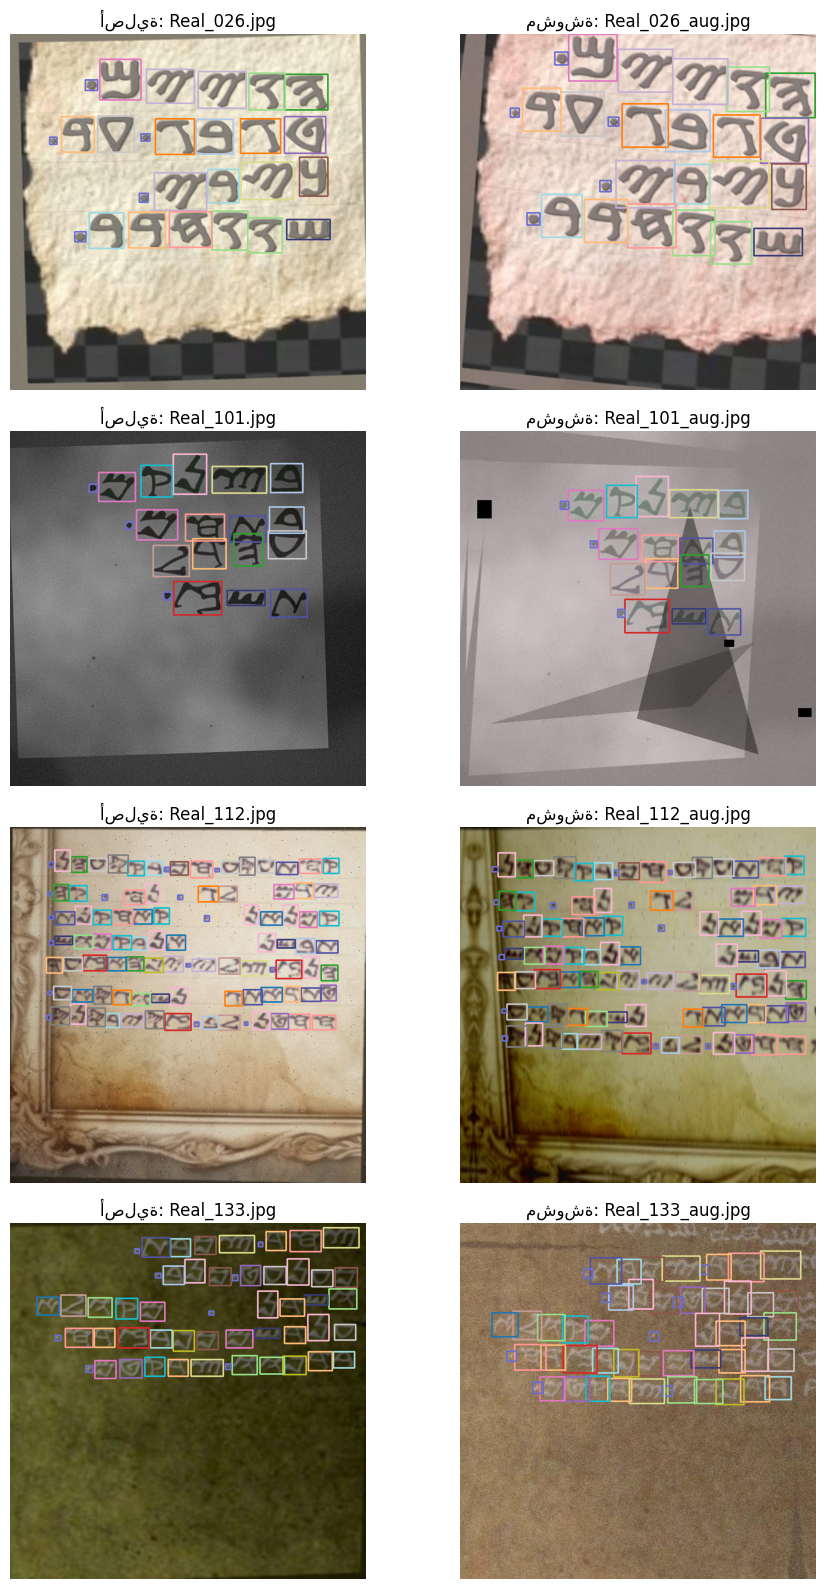

In [ ]:
# ===================== الخلية 7: معاينة أصلية/مشوشة =====================
def draw_yolo_boxes(image_rgb, boxes, classes):
    img = image_rgb.copy()
    h, w = img.shape[:2]
    for (xc, yc, bw, bh), cls in zip(boxes, classes):
        x1 = int((xc - bw / 2) * w); y1 = int((yc - bh / 2) * h)
        x2 = int((xc + bw / 2) * w); y2 = int((yc + bh / 2) * h)
        color = CLASS_COLORS[cls % len(CLASS_COLORS)]
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
    return img

_sample_stems = [p.stem for p in sorted(LOCAL_REAL_IMG_DIR.iterdir())]
_n_preview = min(4, len(_sample_stems))
_sample_stems = random.sample(_sample_stems, _n_preview) if _n_preview else []

fig, axes = plt.subplots(_n_preview, 2, figsize=(10, 4 * max(_n_preview, 1)))
if _n_preview == 1:
    axes = np.array([axes])

for row, stem in enumerate(_sample_stems):
    orig_img_path = next(LOCAL_REAL_IMG_DIR.glob(f"{stem}.*"))
    orig_lbl_path = LOCAL_REAL_LBL_DIR / f"{stem}.txt"
    orig_img = cv2.cvtColor(cv2.imread(str(orig_img_path)), cv2.COLOR_BGR2RGB)
    orig_boxes, orig_classes = read_yolo_label(orig_lbl_path)
    axes[row, 0].imshow(draw_yolo_boxes(orig_img, orig_boxes, orig_classes))
    axes[row, 0].set_title(f"أصلية: {orig_img_path.name}")
    axes[row, 0].axis("off")

    aug_img_path = LOCAL_AUG_IMG_DIR / f"{stem}_aug{orig_img_path.suffix}"
    aug_lbl_path = LOCAL_AUG_LBL_DIR / f"{stem}_aug.txt"
    if aug_img_path.exists():
        aug_img = cv2.cvtColor(cv2.imread(str(aug_img_path)), cv2.COLOR_BGR2RGB)
        aug_boxes, aug_classes = read_yolo_label(aug_lbl_path)
        axes[row, 1].imshow(draw_yolo_boxes(aug_img, aug_boxes, aug_classes))
        axes[row, 1].set_title(f"مشوشة: {aug_img_path.name}")
    else:
        axes[row, 1].set_title("لا توجد نسخة مشوشة")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()


تقسّم الصور على مستوى **الصورة الأصلية** (وليس على مستوى الملفات الأربعمئة) إلى تدريب/تحقق/اختبار بذرة عشوائية ثابتة، ثم تضع كل صورة أصلية ونسخـتها المشوشة معا في نفس المجموعة — هذا يمنع أي تسرّب بيانات (نفس المحتوى لا يظهر في مجموعتين مختلفتين). بعدها تُبنى مجلدات YOLO القياسية `images/{train,val,test}` و`labels/{train,val,test}` محليا في كولاب.

In [ ]:
# ===================== الخلية 8: تقسيم 70/15/15 وبناء هيكل YOLO =====================
base_ids = [p.stem for p in sorted(LOCAL_REAL_IMG_DIR.iterdir())]
random.Random(FT_CONFIG["split"]["seed"]).shuffle(base_ids)

n = len(base_ids)
n_train = int(round(n * FT_CONFIG["split"]["train"]))
n_val = int(round(n * FT_CONFIG["split"]["val"]))
n_test = n - n_train - n_val  # الباقي، لضمان تغطية 100% رغم التقريب

train_ids = set(base_ids[:n_train])
val_ids = set(base_ids[n_train:n_train + n_val])
test_ids = set(base_ids[n_train + n_val:])

def id_to_split(base_id):
    if base_id in train_ids:
        return "train"
    if base_id in val_ids:
        return "val"
    return "test"

print(f"تقسيم على مستوى {n} صورة أصلية (كل صورة ونسخـتها المشوشة تبقيان معا في نفس المجموعة):")
print(f"  تدريب  (train): {len(train_ids)} أصلية")
print(f"  تحقق   (val)  : {len(val_ids)} أصلية")
print(f"  اختبار (test) : {len(test_ids)} أصلية")

for split in ("train", "val", "test"):
    (LOCAL_DATASET_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (LOCAL_DATASET_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

split_counts = Counter()
for img_path in sorted(LOCAL_REAL_IMG_DIR.iterdir()):
    base_id = img_path.stem
    split = id_to_split(base_id)
    lbl_path = LOCAL_REAL_LBL_DIR / f"{base_id}.txt"

    shutil.copy2(img_path, LOCAL_DATASET_DIR / "images" / split / img_path.name)
    shutil.copy2(lbl_path, LOCAL_DATASET_DIR / "labels" / split / f"{base_id}.txt")
    split_counts[split] += 1

    aug_img_path = LOCAL_AUG_IMG_DIR / f"{base_id}_aug{img_path.suffix}"
    aug_lbl_path = LOCAL_AUG_LBL_DIR / f"{base_id}_aug.txt"
    if aug_img_path.exists() and aug_lbl_path.exists():
        shutil.copy2(aug_img_path, LOCAL_DATASET_DIR / "images" / split / aug_img_path.name)
        shutil.copy2(aug_lbl_path, LOCAL_DATASET_DIR / "labels" / split / aug_lbl_path.name)
        split_counts[split] += 1

print("\nعدد الصور الفعلي في كل مجموعة (أصلية + مشوشة):")
for split in ("train", "val", "test"):
    print(f"  {split:5s}: {split_counts[split]}")
print(f"  الإجمالي: {sum(split_counts.values())}")


تقسيم على مستوى 200 صورة أصلية (كل صورة ونسخـتها المشوشة تبقيان معا في نفس المجموعة):
  تدريب  (train): 140 أصلية
  تحقق   (val)  : 30 أصلية
  اختبار (test) : 30 أصلية

عدد الصور الفعلي في كل مجموعة (أصلية + مشوشة):
  train: 278
  val  : 60
  test : 60
  الإجمالي: 398


تكتب `data.yaml` بصيغة Ultralytics YOLO يشير إلى مجلدات كولاب المؤقتة الثلاثة (`train`/`val`/`test`) وبنفس أسماء الأصناف الـ23 المستخدمة في التدريب المسبق.

In [ ]:
# ===================== الخلية 9: كتابة data.yaml =====================
data_yaml_content = {
    "path": str(LOCAL_DATASET_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": NUM_CLASSES,
    "names": CLASS_NAMES,
}

yaml_path = LOCAL_DATASET_DIR / FT_CONFIG["paths"]["data_yaml_filename"]
with open(yaml_path, "w", encoding="utf-8") as f:
    yaml.safe_dump(data_yaml_content, f, allow_unicode=True, sort_keys=False)

print(f"✓ data.yaml: {yaml_path}\n")
print(yaml.safe_dump(data_yaml_content, allow_unicode=True, sort_keys=False))


✓ data.yaml: /content/finetune_work/dataset/data_finetune.yaml

path: /content/finetune_work/dataset
train: images/train
val: images/val
test: images/test
nc: 23
names:
- ALAF
- BIT
- GAMAN
- DALAT
- IY
- BAA
- ZEN
- IT
- TIT
- YUT
- KAAF
- LABAT
- MIM
- NUN
- SINGAAT
- IN
- FI
- TSAADIY
- QUF
- RISH
- SHAN
- TAAF
- DOT



تحمّل وزن الـ Pretraining، وتكمّل تدريبه (fine-tune) بمعدل تعلّم منخفض على بيانات التدريب/التحقق المحلية، وتحفظ كل النتائج (الأوزان، الرسوم البيانية، السجلات) مباشرة في المسار المطلوب على الدرايف: `Real_Image_200/Model_fintune`.

In [ ]:
# ===================== الخلية 10: Fine-Tune Training =====================
PRETRAINED = Path(FT_CONFIG["paths"]["pretrained_weights"])
if not PRETRAINED.exists():
    raise FileNotFoundError(
        f"لم يُعثر على وزن النموذج المُدرَّب مسبقا:\n  {PRETRAINED}\n"
        "تأكد من مسار مخرجات خلية Train في دفتر التوليد/التدريب المسبق، "
        "أو حدّث FT_CONFIG['paths']['pretrained_weights'] أعلاه."
    )

from ultralytics import YOLO

OUT_DIR = Path(FT_CONFIG["paths"]["output_model_dir"])
OUT_DIR.parent.mkdir(parents=True, exist_ok=True)

train_cfg = FT_CONFIG["train"]

model = YOLO(str(PRETRAINED))

train_args = dict(
    data=str(yaml_path),
    imgsz=train_cfg["imgsz"],
    epochs=train_cfg["epochs"],
    batch=train_cfg["batch"],
    patience=train_cfg["patience"],
    lr0=train_cfg["lr0"],
    lrf=train_cfg["lrf"],
    optimizer=train_cfg["optimizer"],
    freeze=train_cfg["freeze"] if train_cfg["freeze"] else None,
    device=train_cfg["device"],
    workers=train_cfg["workers"],
    fliplr=train_cfg["fliplr"],
    flipud=train_cfg["flipud"],
    degrees=train_cfg["degrees"],
    mosaic=train_cfg["mosaic"],
    close_mosaic=train_cfg["close_mosaic"],
    hsv_h=train_cfg["hsv_h"],
    hsv_s=train_cfg["hsv_s"],
    hsv_v=train_cfg["hsv_v"],
    project=str(OUT_DIR.parent),
    name=OUT_DIR.name,
    exist_ok=True,
    save=True,
    val=True,
    plots=True,
)

print("=" * 70)
print("FINE-TUNING")
print("=" * 70)
for k, v in train_args.items():
    print(f"{k:12s}: {v}")
print("=" * 70)

results = model.train(**train_args)

best_pt = OUT_DIR / "weights" / "best.pt"
last_pt = OUT_DIR / "weights" / "last.pt"

print("\n" + "=" * 70)
print("انتهى التدريب")
print("=" * 70)
print(f"مجلد الحفظ : {OUT_DIR}")
print(f"أفضل وزن   : {best_pt}")
print(f"آخر وزن    : {last_pt}")


تقيّم أفضل وزن (`best.pt`) الناتج على مجموعة **الاختبار** المعزولة (15%) التي لم يرَها النموذج إطلاقا أثناء التدريب أو التحقق، وتطبع Precision وRecall وmAP@50 وmAP@50-95.

In [ ]:
# ===================== الخلية 11: تقييم على الاختبار =====================
from ultralytics import YOLO

eval_model = YOLO(str(best_pt))
metrics = eval_model.val(
    data=str(yaml_path),
    split="test",
    imgsz=train_cfg["imgsz"],
    device=train_cfg["device"],
)

print("=" * 50)
print("نتائج التقييم على مجموعة الاختبار (test)")
print("=" * 50)
print(f"Precision  : {metrics.box.mp:.4f}")
print(f"Recall     : {metrics.box.mr:.4f}")
print(f"mAP@50     : {metrics.box.map50:.4f}")
print(f"mAP@50-95  : {metrics.box.map:.4f}")


خلية تفاعلية أخيرة: ارفع صورة من جهازك، يعرضها النموذج المُدرَّب (fine-tuned) مع رسم كل صندوق واسم الحرف المتوقع، ثم يستخرج النص المقروء منها (تجميع الصناديق في أسطر حسب الإحداثي الرأسي، وترتيب كل سطر من اليمين إلى اليسار، مع اعتبار صنف DOT فاصلا بين الكلمات).

In [ ]:
# ===================== الخلية 12: اختبار تفاعلي على صورة مرفوعة =====================
from google.colab import files

# غيّر هذا إن أردت استخدام وزن آخر غير أفضل نتيجة لهذا التدريب
INFER_MODEL_PATH = best_pt
INFER_CONF = 0.25

infer_model = YOLO(str(INFER_MODEL_PATH))

def cluster_into_lines(boxes, y_tol_frac=0.6):
    '''تجميع الصناديق في أسطر حسب مركزها الرأسي، ثم ترتيب كل سطر من اليمين لليسار (RTL).'''
    if not boxes:
        return []
    boxes_sorted = sorted(boxes, key=lambda b: b["yc"])
    med_h = float(np.median([b["h"] for b in boxes_sorted]))
    lines, current = [], [boxes_sorted[0]]
    for b in boxes_sorted[1:]:
        ref_y = np.mean([c["yc"] for c in current])
        if abs(b["yc"] - ref_y) <= y_tol_frac * med_h:
            current.append(b)
        else:
            lines.append(current)
            current = [b]
    lines.append(current)
    for line in lines:
        line.sort(key=lambda b: -b["xc"])  # يمين -> يسار
    return lines

def lines_to_text(lines):
    '''صنف DOT يُعامَل كفاصل كلمات (مسافة)؛ بقية الأصناف تُحوَّل إلى حرف يونيكود السامري الفعلي.'''
    out = []
    for line in lines:
        chars = []
        for b in line:
            if b["cls"] == DOT_CLASS_ID:
                chars.append(" ")
            else:
                chars.append(chr(LETTER_CODEPOINTS[b["cls"]]))
        out.append("".join(chars).strip())
    return "\n".join(out)

def run_inference_on_upload():
    print("اختر صورة من جهازك لرفعها...")
    uploaded = files.upload()
    for fname in uploaded:
        img_bgr = cv2.imread(fname)
        if img_bgr is None:
            print(f"⚠ تعذّرت قراءة الصورة: {fname}")
            continue
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]

        result = infer_model.predict(
            source=fname, imgsz=train_cfg["imgsz"], conf=INFER_CONF, max_det=1500, verbose=False
        )[0]

        boxes = []
        if result.boxes is not None:
            for xyxy, cls, cf in zip(
                result.boxes.xyxy.cpu().numpy(),
                result.boxes.cls.cpu().numpy(),
                result.boxes.conf.cpu().numpy(),
            ):
                x1, y1, x2, y2 = xyxy
                boxes.append({
                    "cls": int(cls), "conf": float(cf),
                    "xc": (x1 + x2) / 2.0, "yc": (y1 + y2) / 2.0, "h": y2 - y1,
                    "x1": x1, "y1": y1, "x2": x2, "y2": y2,
                })

        vis = img_rgb.copy()
        for b in boxes:
            color = CLASS_COLORS[b["cls"] % len(CLASS_COLORS)]
            cv2.rectangle(vis, (int(b["x1"]), int(b["y1"])), (int(b["x2"]), int(b["y2"])), color, 2)
            label = "DOT" if b["cls"] == DOT_CLASS_ID else CLASS_NAMES[b["cls"]]
            cv2.putText(
                vis, f"{label} {b['conf']:.2f}",
                (int(b["x1"]), max(15, int(b["y1"]) - 5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2,
            )

        plt.figure(figsize=(12, max(4, 12 * h / max(w, 1))))
        plt.imshow(vis)
        plt.axis("off")
        plt.title(f"{fname} — عدد الصناديق المكتشفة: {len(boxes)}")
        plt.show()

        text = lines_to_text(cluster_into_lines(boxes))
        print("النص المستخرج (كل سطر من اليمين لليسار، DOT = فاصل كلمات):")
        print("-" * 50)
        print(text if text.strip() else "(لم يُكتشف أي حرف بثقة كافية — جرّب خفض INFER_CONF)")
        print("-" * 50)

run_inference_on_upload()
